In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv(
    "../data/processed/cleaned_patient_dataset.csv"
)

df.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Chronic_Disease,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol_Level,Blood_Sugar_Level,...,Protein_Intake,Carbohydrate_Intake,Fat_Intake,Preferred_Cuisine,Food_Aversions,Recommended_Calories,Recommended_Protein,Recommended_Carbs,Recommended_Fats,Recommended_Meal_Plan
0,56,Other,163,66,24.84,No Disease,175,75,219,124,...,105,179,143,Western,NaN,2150,108,139,145,High-Protein Diet
1,69,Female,171,114,38.99,No Disease,155,72,208,72,...,69,315,75,Mediterranean,NaN,1527,74,266,80,Low-Carb Diet
2,46,Female,172,119,40.22,No Disease,137,101,171,145,...,183,103,148,Western,Sweet,2359,180,145,143,Low-Carb Diet
3,32,Female,197,118,30.41,No Disease,148,91,258,235,...,135,371,120,Western,NaN,2858,137,378,135,Low-Carb Diet
4,60,Female,156,109,44.79,Hypertension,160,109,260,248,...,167,298,48,Indian,Spicy,1937,166,317,56,Low-Carb Diet


Step 3 — Load Models

In [3]:
regression_model = joblib.load(
    "../models/trained/calorie_prediction_model.pkl"
)

classification_model = joblib.load(
    "../models/trained/diet_classifier.pkl"
)

preprocessor = joblib.load(
    "../models/saved_objects/preprocessor.pkl"
)

In [4]:
X = df.drop(
    columns=[
        "Recommended_Calories",
        "Recommended_Protein",
        "Recommended_Carbs",
        "Recommended_Fats",
        "Recommended_Meal_Plan"
    ]
)

y_reg = df["Recommended_Calories"]

y_cls = df["Recommended_Meal_Plan"]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_reg_train, y_reg_temp, y_cls_train, y_cls_temp = train_test_split(
    X,
    y_reg,
    y_cls,
    test_size=0.30,
    random_state=42,
    stratify=y_cls
)

X_validation, X_test, y_reg_validation, y_reg_test, y_cls_validation, y_cls_test = train_test_split(
    X_temp,
    y_reg_temp,
    y_cls_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_cls_temp
)

In [6]:
X_test = preprocessor.transform(X_test)

REGRESSION EVALUATION

Predict

In [7]:
reg_predictions = regression_model.predict(X_test)

Metrics

In [8]:
mae = mean_absolute_error(
    y_reg_test,
    reg_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        reg_predictions
    )
)

r2 = r2_score(
    y_reg_test,
    reg_predictions
)

print("MAE :", mae)

print("RMSE :", rmse)

print("R² :", r2)

MAE : 104.53377877496055
RMSE : 119.61811231430067
R² : 0.9669196098781632


Actual vs Predicted Plot

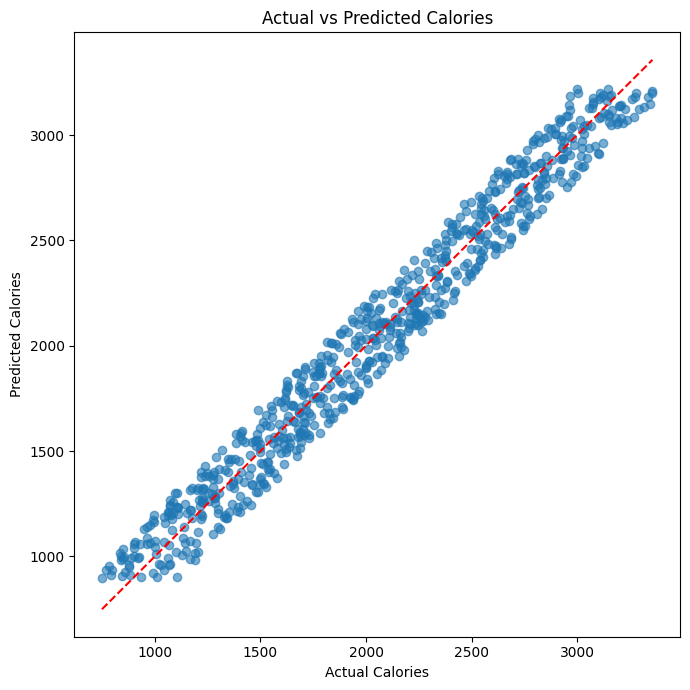

In [9]:
plt.figure(figsize=(7,7))

plt.scatter(
    y_reg_test,
    reg_predictions,
    alpha=0.6
)

plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    'r--'
)

plt.xlabel("Actual Calories")

plt.ylabel("Predicted Calories")

plt.title("Actual vs Predicted Calories")

plt.tight_layout()

plt.savefig(
    "../reports/figures/actual_vs_predicted.png",
    dpi=300
)

plt.show()

Residual Plot

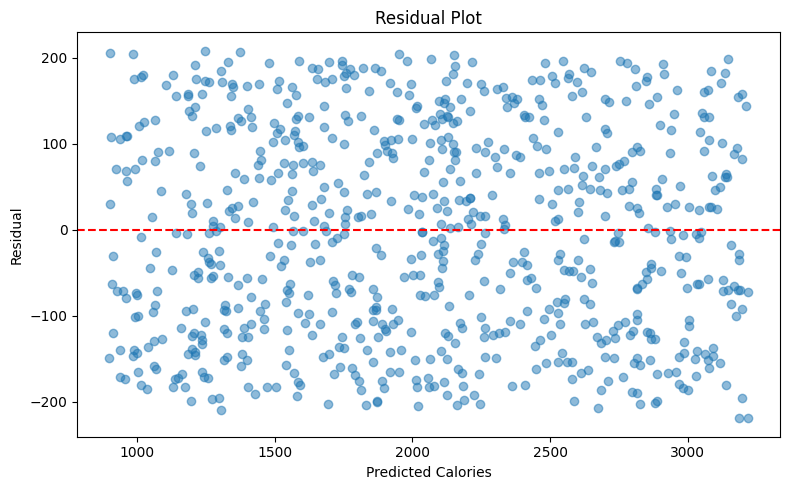

In [10]:
residuals = y_reg_test - reg_predictions

plt.figure(figsize=(8,5))

plt.scatter(
    reg_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Calories")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.tight_layout()

plt.savefig(
    "../reports/figures/residual_plot.png",
    dpi=300
)

plt.show()

CLASSIFICATION EVALUATION

Prediction

In [11]:
cls_predictions = classification_model.predict(
    X_test
)

Report

In [12]:
print(

    classification_report(

        y_cls_test,

        cls_predictions

    )

)

                   precision    recall  f1-score   support

    Balanced Diet       1.00      1.00      1.00        60
High-Protein Diet       1.00      1.00      1.00        72
    Low-Carb Diet       1.00      1.00      1.00       350
     Low-Fat Diet       1.00      1.00      1.00       268

         accuracy                           1.00       750
        macro avg       1.00      1.00      1.00       750
     weighted avg       1.00      1.00      1.00       750



Confusion Matrix

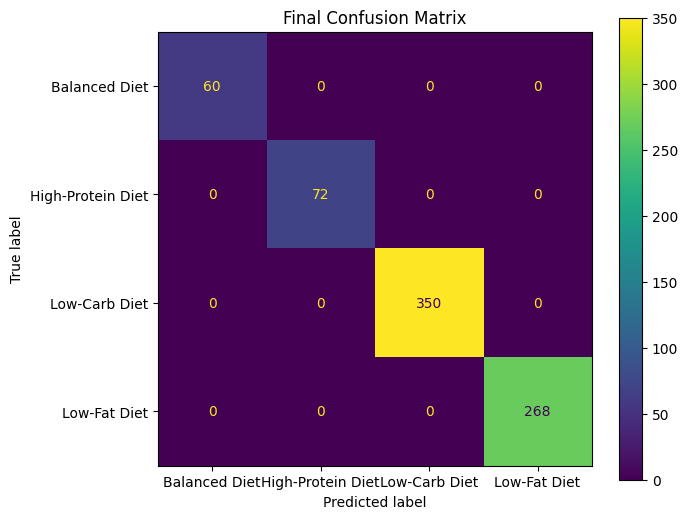

In [13]:
cm = confusion_matrix(

    y_cls_test,

    cls_predictions

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=classification_model.classes_

)

fig, ax = plt.subplots(figsize=(7,6))

disp.plot(ax=ax)

plt.title("Final Confusion Matrix")

plt.savefig(
    "../reports/figures/final_confusion_matrix.png",
    dpi=300
)

plt.show()

FEATURE IMPORTANCE

In [14]:
feature_names = joblib.load(
    "../models/saved_objects/feature_columns.pkl"
)

importance = classification_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
19,cat__Chronic_Disease_Heart Disease,0.247869
18,cat__Chronic_Disease_Diabetes,0.228373
3,num__BMI,0.206399
6,num__Cholesterol_Level,0.180947
8,num__Daily_Steps,0.072862
9,num__Exercise_Frequency,0.063550
2,num__Weight_kg,0.000000
4,num__Blood_Pressure_Systolic,0.000000
5,num__Blood_Pressure_Diastolic,0.000000
7,num__Blood_Sugar_Level,0.000000


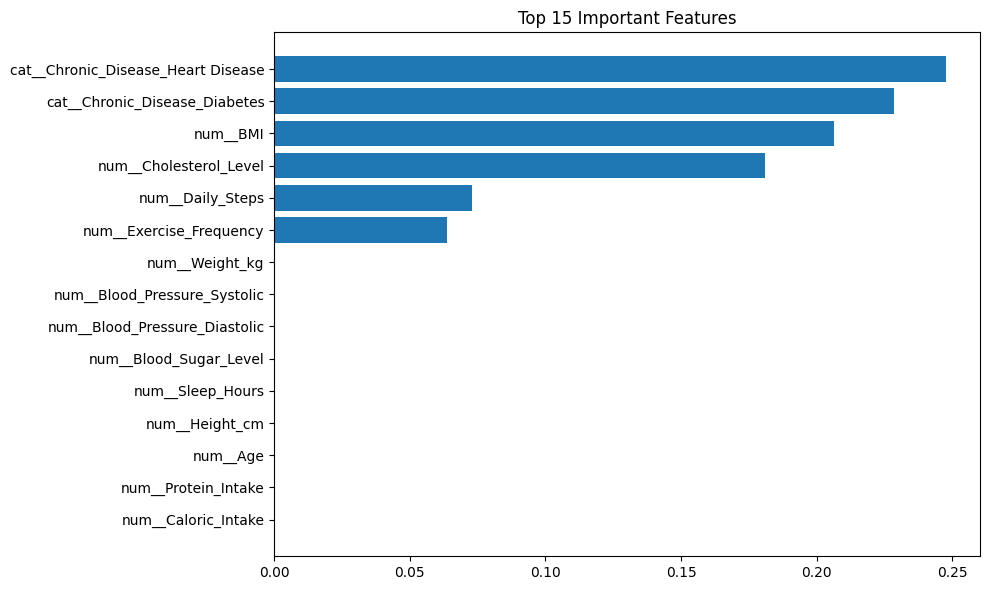

In [15]:
top = importance_df.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top["Feature"],
    top["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Important Features")

plt.tight_layout()

plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300
)

plt.show()

Evaluation report

In [16]:
evaluation = {

    "Regression Model": "Linear Regression",

    "Regression R2": float(r2),

    "Regression MAE": float(mae),

    "Regression RMSE": float(rmse),

    "Classification Model": "Decision Tree",

    "Classification Accuracy": 1.0

}

import json

with open(
    "../reports/metrics/final_evaluation.json",
    "w"
) as f:

    json.dump(
        evaluation,
        f,
        indent=4
    )

print("Final Evaluation Saved")

Final Evaluation Saved
